# VoltBharat — exploratory analysis

Works on the **processed** outputs in `data/processed/` (run `python -m etl.run_pipeline` first). Raw CSVs are never modified. DuckDB queries parquet directly, so this stays memory-light.

EV = BEV (`Electric(BOV)` + `Pure EV`).

In [1]:
import duckdb, pandas as pd
from pathlib import Path
P = Path.cwd().parent / 'data' / 'processed' if Path.cwd().name == 'notebooks' else Path('data/processed')
con = duckdb.connect()
fuel = f"read_parquet('{(P/'fuel_state_month.parquet').as_posix()}')"
con.sql(f'select count(*) rows, min(month), max(month), count(distinct state_name) states from {fuel}').df()

,rows,"min(""month"")","max(""month"")",states
0,20840,2022-01-01,2026-09-01,36


## The label migration: `Electric(BOV)` → `Pure EV`
Both labels are battery-electric; the combined series is continuous.

In [2]:
con.sql(f"""select month, sum(registrations) filter (where fuel_label='Electric(BOV)') bov,
  sum(registrations) filter (where fuel_label='Pure EV') pure_ev, sum(registrations) filter (where is_bev) bev
from {fuel} where month between '2023-10-01' and '2024-12-01' group by 1 order by 1""").df()

,month,bov,pure_ev,bev
0,2023-10-01,143852.0,1.0,143853.0
1,2023-11-01,158626.0,2.0,158628.0
2,2023-12-01,147577.0,8.0,147585.0
3,2024-01-01,151222.0,276.0,151498.0
4,2024-02-01,148706.0,1.0,148707.0
5,2024-03-01,219975.0,3227.0,223202.0
6,2024-04-01,116233.0,2516.0,118749.0
7,2024-05-01,128724.0,16689.0,145413.0
8,2024-06-01,115569.0,30660.0,146229.0
9,2024-07-01,137792.0,51472.0,189264.0


## National monthly BEV share

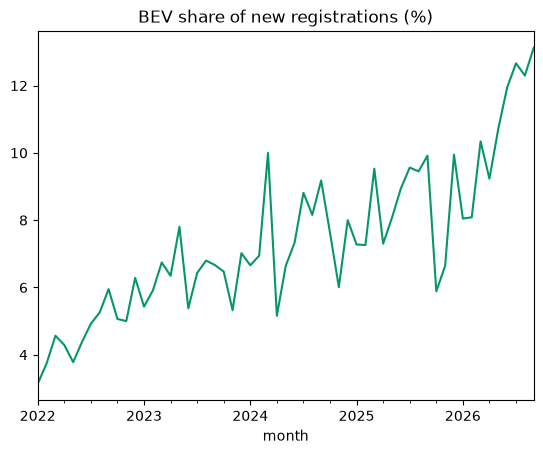

In [3]:
m = con.sql(f"select month, sum(registrations) filter (where is_bev) bev, sum(registrations) total from {fuel} group by 1 order by 1").df()
m['ev_share_pct'] = 100 * m.bev / m.total
ax = m.plot(x='month', y='ev_share_pct', legend=False, title='BEV share of new registrations (%)', color='#059669')

## Seasonality: average BEV registrations by calendar month (complete years only)

In [4]:
s = con.sql(f"""select month(month) m, avg(bev) avg_bev from (select month, sum(registrations) filter (where is_bev) bev from {fuel}
  where year(month) between 2022 and 2025 group by 1) group by 1 order by 1""").df()
s

,m,avg_bev
0,1,123084.25
1,2,116434.25
2,3,166941.00
3,4,122392.25
4,5,142368.50
5,6,129506.75
6,7,147463.75
7,8,145088.25
8,9,147056.00
9,10,183554.50


## State concentration (Herfindahl index of BEV registrations by year)

In [5]:
con.sql(f"""with y as (select year(month) yr, state_name, sum(registrations) filter (where is_bev) bev from {fuel} group by 1, 2),
s as (select yr, bev / sum(bev) over (partition by yr) share from y)
select yr, round(10000 * sum(share * share)) hhi from s group by yr order by yr""").df()

,yr,hhi
0,2022,766.0
1,2023,802.0
2,2024,793.0
3,2025,764.0
4,2026,707.0


## Category data validation (all fuels; not EV-specific)
Cleaned category totals vs the fuel source, Jan-2022..May-2024.

In [6]:
pd.read_csv(P / 'category_state_check.csv').sort_values('ratio', ascending=False)

,state_name,category_total,fuel_total,ratio,within_5pct
0,Arunachal Pradesh,35313209,73455,480.7462,False
1,Rajasthan,54965892,3437917,15.9881,False
2,Andhra Pradesh,31332190,2115730,14.8092,False
3,Kerala,15298889,1857045,8.2383,False
4,Tripura,158512,135815,1.1671,False
5,Dadra and Nagar Haveli and Daman and Diu,51524,51110,1.0081,True
6,Gujarat,4057357,4034746,1.0056,True
7,Sikkim,26440,26387,1.0020,True
8,Himachal Pradesh,304728,304429,1.0010,True
9,Meghalaya,94968,94894,1.0008,True
